# SwiftBasket case study: which growth is worth having?
**Aritra Pal · PGPM 2027, Great Lakes Institute of Management, Chennai · Straive case study #1**

The COO's question: SwiftBasket is growing, but is the growth healthy? Where should we lean in, and where should we pull back?

How I worked:
1. Loaded the four sheets of the case workbook into a small SQL database (SQLite).
2. Made a few bar charts here, and built the dashboards in Tableau Public.

Where I used AI: I used Claude (an AI assistant) to help write the code and draft the text. I checked the main numbers again in plain Python at the end of this notebook (section 7), and they match the SQL.

## Step 0 · Load the data into SQL

In [1]:
import glob, os, sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Find the Excel file (works on my laptop and on Kaggle)
paths = ["../data/SwiftBasket_2026_Case_Data.xlsx", "data/SwiftBasket_2026_Case_Data.xlsx"] + \
        glob.glob("/kaggle/input/**/*SwiftBasket*.xlsx", recursive=True)
excel_file = [p for p in paths if os.path.exists(p)][0]
print("Using:", excel_file)

# Put each sheet into a SQLite table with the same name
con = sqlite3.connect(":memory:")
for sheet in ["orders", "customers", "stores", "campaign_assignments"]:
    pd.read_excel(excel_file, sheet_name=sheet).to_sql(sheet, con, index=False)

# Small helper: run a SQL query and show the result as a table
def run(sql):
    return pd.read_sql(sql, con)

Using: /kaggle/input/datasets/aritrapal3196/swiftbasket/SwiftBasket_2026_Case_Data.xlsx


In [2]:
# Chart settings, so every chart looks the same
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 11})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b7b0"
CHARTS = "../charts" if os.path.isdir("../charts") else "charts"
os.makedirs(CHARTS, exist_ok=True)

def bar_chart(df, x, y, title, ylabel, highlight=None, fmt="{:.0f}", fname=None):
    colors = [ORANGE if highlight is not None and i in highlight else BLUE for i in range(len(df))]
    ax = df.plot(kind="bar", x=x, y=y, legend=False, color=colors, rot=0, width=0.6)
    for i, v in enumerate(df[y]):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom" if v >= 0 else "top", fontweight="bold")
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel); ax.set_xlabel("")
    ax.axhline(0, color="#888", linewidth=0.8)
    if fname: plt.savefig(f"{CHARTS}/{fname}.png", dpi=200, bbox_inches="tight")
    plt.show()

## Step 1 · Get to know the tables

In [3]:
df = run("""
SELECT 'orders' AS table_name, COUNT(*) AS row_count FROM orders
UNION ALL SELECT 'customers', COUNT(*) FROM customers
UNION ALL SELECT 'stores', COUNT(*) FROM stores
UNION ALL SELECT 'campaign_assignments', COUNT(*) FROM campaign_assignments
""")
df

,table_name,row_count
0,orders,30000
1,customers,8000
2,stores,36
3,campaign_assignments,8000


In [4]:
df = run("""
SELECT * FROM orders LIMIT 5
""")
df

,order_id,customer_id,store_id,order_timestamp,promised_minutes,actual_delivery_minutes,basket_value_inr,discount_inr,delivery_fee_inr,gross_margin_inr,...,unique_category_count,stockout_item_count,substitution_count,delivery_distance_km,weather_flag,peak_period_flag,cancelled_flag,late_delivery_flag,service_contact_flag,rating
0,O0000001,C004264,S013,2025-06-08 21:11:00,30,19.0,657.44,37,29,173.46,...,5,2,2,1.40,Normal,1,0,0.0,1,4.0
1,O0000002,C006073,S035,2025-06-08 11:45:00,30,8.0,470.05,58,0,114.44,...,2,0,0,4.12,Normal,0,0,0.0,0,5.0
2,O0000003,C002271,S024,2025-10-17 22:12:00,20,12.0,558.94,6,0,180.48,...,4,0,0,0.87,Normal,0,0,0.0,0,5.0
3,O0000004,C006477,S025,2025-04-14 16:49:00,30,20.0,532.61,63,0,136.81,...,5,0,0,1.88,Heat,0,0,0.0,0,NaN
4,O0000005,C006501,S007,2025-03-24 11:18:00,25,12.0,589.65,12,0,157.88,...,5,1,1,1.93,Normal,0,0,0.0,0,4.0


In [5]:
df = run("""
SELECT MIN(order_timestamp) AS first_order, MAX(order_timestamp) AS last_order FROM orders
""")
df

,first_order,last_order
0,2025-01-01 08:19:00,2025-12-31 23:30:00


What I see: 30,000 orders from 1 Jan to 31 Dec 2025, 8,000 customers and 36 stores. One row in `orders` is one order.

One check before going further. **Contribution margin** is what an order leaves us after discounts, picking, delivery and refunds, before fixed costs like rent. The Data Dictionary gives its formula, so I check that the column follows it:

In [6]:
df = run("""
SELECT ROUND(SUM(gross_margin_inr + delivery_fee_inr - discount_inr - picking_cost_inr
                 - delivery_cost_inr - refund_inr - contribution_margin_inr), 2) AS difference
FROM orders
""")
df

,difference
0,0.0


The difference is 0, so the column is reliable and I can use it directly.

## Step 2 · Business health (Ask 1)
Question: at a glance, how healthy is SwiftBasket?

In [7]:
kpi = run("""
SELECT COUNT(*)                                                         AS orders,
       ROUND(AVG(basket_value_inr), 0)                                  AS avg_basket_inr,
       ROUND(AVG(contribution_margin_inr), 1)                           AS margin_per_order_inr,
       ROUND(100.0 * SUM(contribution_margin_inr) / SUM(basket_value_inr), 1) AS margin_pct_of_sales,
       ROUND(100.0 * AVG(CASE WHEN contribution_margin_inr < 0 THEN 1 ELSE 0 END), 1) AS pct_orders_losing_money,
       ROUND(100.0 * AVG(late_delivery_flag), 1)                        AS pct_late,
       ROUND(100.0 * AVG(cancelled_flag), 1)                            AS pct_cancelled,
       ROUND(AVG(rating), 2)                                            AS avg_rating
FROM orders
""")
kpi

,orders,avg_basket_inr,margin_per_order_inr,margin_pct_of_sales,pct_orders_losing_money,pct_late,pct_cancelled,avg_rating
0,30000,560.0,44.3,7.9,21.0,17.3,1.0,4.21


In [8]:
money = run("""
SELECT ROUND(AVG(gross_margin_inr), 0)   AS product_margin,
       ROUND(AVG(delivery_fee_inr), 0)   AS delivery_fee_paid_by_customer,
       ROUND(AVG(discount_inr), 0)       AS discount,
       ROUND(AVG(picking_cost_inr), 0)   AS picking_cost,
       ROUND(AVG(delivery_cost_inr), 0)  AS delivery_cost,
       ROUND(AVG(refund_inr), 0)         AS refund,
       ROUND(AVG(contribution_margin_inr), 0) AS margin_left
FROM orders
""")
money

,product_margin,delivery_fee_paid_by_customer,discount,picking_cost,delivery_cost,refund,margin_left
0,161.0,6.0,45.0,21.0,36.0,21.0,44.0


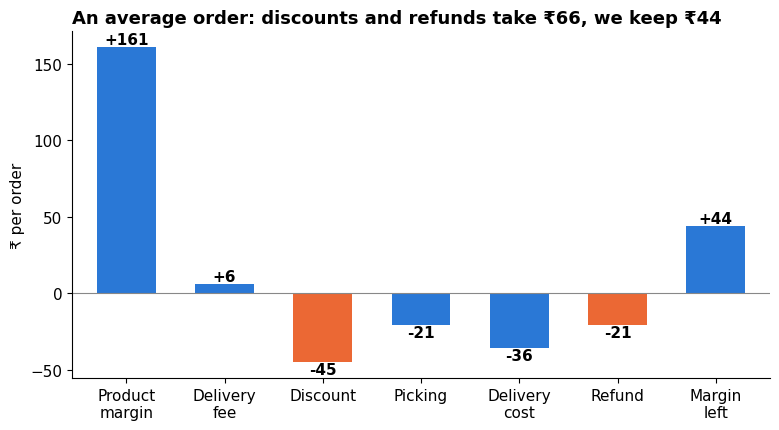

In [9]:
steps = pd.DataFrame({
    "item": ["Product\nmargin", "Delivery\nfee", "Discount", "Picking", "Delivery\ncost", "Refund", "Margin\nleft"],
    "inr":  [money.product_margin[0], money.delivery_fee_paid_by_customer[0], -money.discount[0],
             -money.picking_cost[0], -money.delivery_cost[0], -money.refund[0], money.margin_left[0]]})
bar_chart(steps, "item", "inr", "An average order: discounts and refunds take ₹66, we keep ₹44",
          "₹ per order", highlight=[2, 5], fmt="{:+.0f}", fname="1_where_the_money_goes")

In [10]:
monthly = run("""
SELECT strftime('%m', order_timestamp)          AS month,
       COUNT(*)                                 AS orders,
       ROUND(AVG(contribution_margin_inr), 1)   AS margin_per_order,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late,
       ROUND(100.0 * AVG(CASE WHEN weather_flag = 'Rain' THEN 1 ELSE 0 END), 0) AS pct_orders_in_rain
FROM orders
GROUP BY month
ORDER BY month
""")
monthly

,month,orders,margin_per_order,pct_late,pct_orders_in_rain
0,01,2505,44.4,14.9,12.0
1,02,2251,43.3,14.0,12.0
2,03,2547,45.5,14.0,13.0
3,04,2499,42.1,18.3,10.0
4,05,2520,45.0,17.0,10.0
5,06,2414,45.1,21.7,39.0
6,07,2476,46.0,19.3,41.0
7,08,2573,44.6,20.4,40.0
8,09,2531,41.3,21.2,40.0
9,10,2626,47.1,15.2,12.0


What I see:
- An average order brings in about ₹167 (₹161 product margin plus a ₹6 delivery fee). Discounts (₹45) and refunds (₹21) take ₹66 of that, more than the ₹44 we keep.
- Margin is 7.9% of sales, and 1 in 5 orders loses money.
- About 17% of orders arrive later than promised. Cancellations are only 1%, so they aren't the problem.
- Volume is flat, about 2,500 orders every month. Lateness goes up from June to September, the months when about 40% of orders are placed in rain (vs 12% in other months).

So the right headline number for leadership is **margin per order**, not order count.

## Step 3 · Which customers are worth having? (Ask 2)
Question: what goes with customers coming back, and with them being profitable?

In [11]:
disc = run("""
SELECT CASE WHEN discount_inr = 0   THEN '1. No discount'
            WHEN discount_inr <= 25 THEN '2. ₹1-25'
            WHEN discount_inr <= 50 THEN '3. ₹26-50'
            WHEN discount_inr <= 75 THEN '4. ₹51-75'
            ELSE '5. ₹76+' END                AS discount_size,
       COUNT(*)                               AS orders,
       ROUND(AVG(basket_value_inr), 0)        AS avg_basket,
       ROUND(AVG(contribution_margin_inr), 1) AS margin_per_order
FROM orders
GROUP BY discount_size
ORDER BY discount_size
""")
disc

,discount_size,orders,avg_basket,margin_per_order
0,1. No discount,1230,559.0,87.1
1,2. ₹1-25,5604,559.0,72.3
2,3. ₹26-50,11196,561.0,49.7
3,4. ₹51-75,8631,559.0,28.2
4,5. ₹76+,3339,557.0,4.9


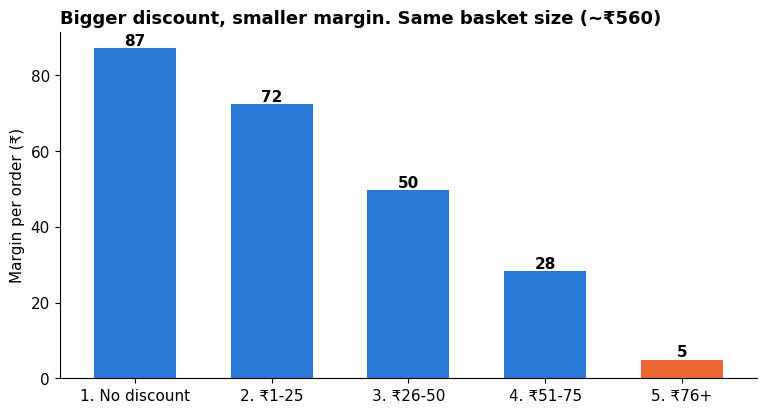

In [12]:
bar_chart(disc, "discount_size", "margin_per_order", "Bigger discount, smaller margin. Same basket size (~₹560)",
          "Margin per order (₹)", highlight=[4], fname="2_discount_vs_margin")

In [13]:
freq = run("""
SELECT CASE WHEN c.historical_orders_12m = 1  THEN '1. 1 order'
            WHEN c.historical_orders_12m <= 3 THEN '2. 2-3 orders'
            WHEN c.historical_orders_12m <= 6 THEN '3. 4-6 orders'
            WHEN c.historical_orders_12m <= 10 THEN '4. 7-10 orders'
            ELSE '5. 11+ orders' END             AS orders_in_2025,
       COUNT(DISTINCT c.customer_id)              AS customers,
       ROUND(AVG(o.discount_inr), 0)              AS avg_discount,
       ROUND(AVG(o.contribution_margin_inr), 1)   AS margin_per_order
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY orders_in_2025
ORDER BY orders_in_2025
""")
freq

,orders_in_2025,customers,avg_discount,margin_per_order
0,1. 1 order,1295,33.0,56.6
1,2. 2-3 orders,2149,36.0,52.3
2,3. 4-6 orders,1850,40.0,49.4
3,4. 7-10 orders,982,48.0,41.1
4,5. 11+ orders,483,57.0,32.1


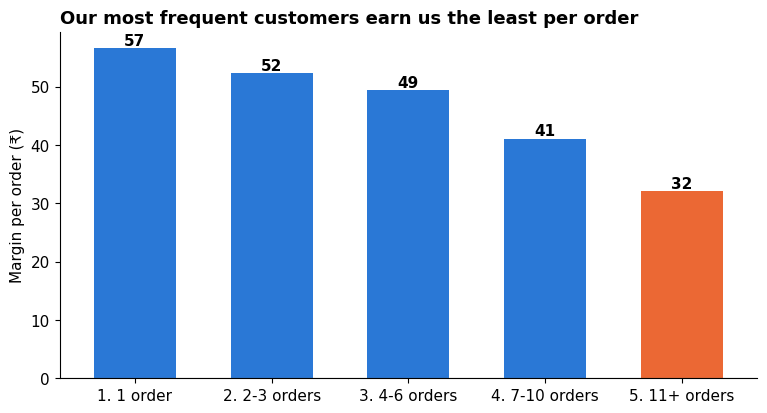

In [14]:
bar_chart(freq, "orders_in_2025", "margin_per_order", "Our most frequent customers earn us the least per order",
          "Margin per order (₹)", highlight=[4], fname="3_frequent_customers")

In [15]:
df = run("""
SELECT 'Membership' AS split, membership_status AS grp, COUNT(*) AS customers,
       ROUND(100.0 * AVG(repeat_order_30d), 1) AS pct_repeat
FROM customers GROUP BY membership_status
UNION ALL
SELECT 'Channel', acquisition_channel, COUNT(*), ROUND(100.0 * AVG(repeat_order_30d), 1)
FROM customers GROUP BY acquisition_channel
UNION ALL
SELECT 'City tier', city_tier, COUNT(*), ROUND(100.0 * AVG(repeat_order_30d), 1)
FROM customers GROUP BY city_tier
""")
df

,split,grp,customers,pct_repeat
0,Membership,Annual member,1612,31.6
1,Membership,Monthly member,2017,31.0
2,Membership,Non-member,4371,30.1
3,Channel,Affiliate,1178,29.7
4,Channel,Marketplace,1198,31.9
5,Channel,Organic,2390,31.7
6,Channel,Paid Social,2015,29.9
7,Channel,Referral,1219,29.7
8,City tier,Metro,4026,31.0
9,City tier,Tier 2,3974,30.3


In [16]:
df = run("""
SELECT first_order_offer_inr, COUNT(*) AS customers,
       ROUND(100.0 * AVG(repeat_order_30d), 1) AS pct_repeat
FROM customers
GROUP BY first_order_offer_inr
""")
df

,first_order_offer_inr,customers,pct_repeat
0,0,2261,30.5
1,50,1138,30.6
2,75,1134,29.3
3,100,1198,32.8
4,112,1145,29.9
5,150,1124,31.0


In [17]:
app = run("""
SELECT CASE WHEN app_sessions_30d <= 3  THEN '1. 0-3 sessions'
            WHEN app_sessions_30d <= 7  THEN '2. 4-7 sessions'
            WHEN app_sessions_30d <= 12 THEN '3. 8-12 sessions'
            ELSE '4. 13+ sessions' END AS app_use,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(repeat_order_30d), 1) AS pct_repeat
FROM customers
GROUP BY app_use
ORDER BY app_use
""")
app

,app_use,customers,pct_repeat
0,1. 0-3 sessions,2013,10.4
1,2. 4-7 sessions,2127,21.1
2,3. 8-12 sessions,2074,34.0
3,4. 13+ sessions,1786,61.0


What I see:
- **Discounts eat margin.** Basket size is the same (~₹560) whatever the discount, so the discount isn't making people buy more. An order with no discount leaves ₹87; an order with ₹76+ off leaves ₹5.
- **Our busiest customers earn us the least per order.** Customers with 11+ orders a year get ₹57 off on average, against ₹33 for one-time customers, so their margin per order is ₹32 against ₹57. They're still worth keeping, but they don't need such big discounts. This is the COO's worry, and the data partly backs it.
- **Membership, channel, city tier and the size of the first-order offer make almost no difference** to repeat rates (all between 29% and 33%).
- **App use does.** Customers with 13+ app sessions a month repeat at 61%, against 10% for 0-3 sessions. (This shows the two go together, not that one causes the other.)

## Step 4 · Operations: where are we losing money? (Ask 3)

In [18]:
df = run("""
SELECT promised_minutes, COUNT(*) AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late,
       ROUND(AVG(delivery_distance_km), 1)        AS avg_distance_km
FROM orders
GROUP BY promised_minutes
""")
df

,promised_minutes,orders,pct_late,avg_distance_km
0,20,7442,40.4,2.5
1,25,7464,17.8,2.5
2,30,15094,5.6,2.5


In [19]:
promise = run("""
SELECT CASE WHEN delivery_distance_km <= 2 THEN '1. 0-2 km'
            WHEN delivery_distance_km <= 4 THEN '2. 2-4 km'
            ELSE '3. over 4 km' END AS distance,
       promised_minutes,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late
FROM orders
GROUP BY distance, promised_minutes
ORDER BY distance, promised_minutes
""")
promise

,distance,promised_minutes,orders,pct_late
0,1. 0-2 km,20,2739,22.3
1,1. 0-2 km,25,2747,5.4
2,1. 0-2 km,30,5520,1.1
3,2. 2-4 km,20,3771,45.7
4,2. 2-4 km,25,3786,19.6
5,2. 2-4 km,30,7609,5.2
6,3. over 4 km,20,932,72.5
7,3. over 4 km,25,931,47.2
8,3. over 4 km,30,1965,19.8


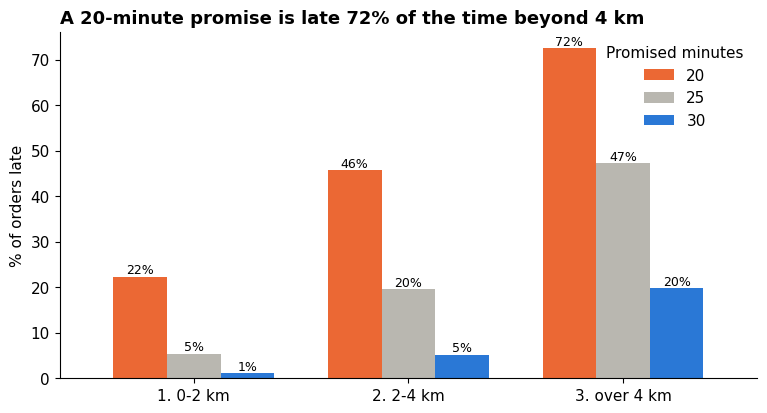

promised_minutes,20,25,30
distance,,,
1. 0-2 km,22.3,5.4,1.1
2. 2-4 km,45.7,19.6,5.2
3. over 4 km,72.5,47.2,19.8


In [20]:
table = promise.pivot(index="distance", columns="promised_minutes", values="pct_late")
ax = table.plot(kind="bar", rot=0, color=[ORANGE, GREY, BLUE], width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", fontsize=9)
ax.set_title("A 20-minute promise is late 72% of the time beyond 4 km", loc="left")
ax.set_ylabel("% of orders late"); ax.set_xlabel(""); ax.legend(title="Promised minutes", frameon=False)
plt.savefig(f"{CHARTS}/4_promise_vs_distance.png", dpi=200, bbox_inches="tight"); plt.show()
table

In [21]:
df = run("""
SELECT weather_flag,
       CASE WHEN peak_period_flag = 1 THEN 'Peak hours' ELSE 'Other hours' END AS time_of_day,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late
FROM orders
GROUP BY weather_flag, time_of_day
ORDER BY pct_late DESC
""")
df

,weather_flag,time_of_day,orders,pct_late
0,Rain,Peak hours,2293,47.5
1,Heat,Peak hours,1257,31.7
2,Rain,Other hours,4036,24.1
3,Normal,Peak hours,7520,20.1
4,Heat,Other hours,2156,15.3
5,Normal,Other hours,12738,6.9


In [22]:
df = run("""
SELECT CASE WHEN late_delivery_flag = 1 THEN 'Late' ELSE 'On time' END AS delivery,
       COUNT(*) AS orders,
       ROUND(AVG(rating), 2) AS avg_rating,
       ROUND(100.0 * AVG(service_contact_flag), 1) AS pct_contacted_support
FROM orders
WHERE cancelled_flag = 0
GROUP BY delivery
""")
df

,delivery,orders,avg_rating,pct_contacted_support
0,Late,5130,3.88,18.8
1,On time,24565,4.28,11.1


In [23]:
stock = run("""
SELECT CASE WHEN stockout_item_count = 0 THEN '0 missing'
            WHEN stockout_item_count = 1 THEN '1 missing'
            WHEN stockout_item_count = 2 THEN '2 missing'
            ELSE '3+ missing' END              AS items_missing,
       COUNT(*)                                 AS orders,
       ROUND(AVG(refund_inr), 1)                AS avg_refund,
       ROUND(AVG(rating), 2)                    AS avg_rating,
       ROUND(AVG(contribution_margin_inr), 1)   AS margin_per_order
FROM orders
GROUP BY items_missing
ORDER BY items_missing
""")
stock

,items_missing,orders,avg_refund,avg_rating,margin_per_order
0,0 missing,10815,10.3,4.95,56.6
1,1 missing,9741,27.7,4.23,39.3
2,2 missing,5475,27.5,3.69,35.9
3,3+ missing,3969,27.4,2.94,34.4


In [24]:
inv = run("""
SELECT CASE WHEN s.inventory_accuracy_pct < 90 THEN '1. Below 90%'
            WHEN s.inventory_accuracy_pct < 95 THEN '2. 90-95%'
            ELSE '3. 95% and above' END             AS stock_accuracy,
       COUNT(DISTINCT s.store_id)                   AS stores,
       COUNT(*)                                     AS orders,
       ROUND(AVG(o.stockout_item_count), 2)         AS missing_items_per_order,
       ROUND(AVG(o.refund_inr), 1)                  AS refund_per_order,
       ROUND(AVG(o.contribution_margin_inr), 1)     AS margin_per_order,
       ROUND(AVG(o.rating), 2)                      AS avg_rating
FROM orders o
JOIN stores s ON o.store_id = s.store_id
GROUP BY stock_accuracy
ORDER BY stock_accuracy
""")
inv

,stock_accuracy,stores,orders,missing_items_per_order,refund_per_order,margin_per_order,avg_rating
0,1. Below 90%,9,7414,1.77,26.7,38.7,3.83
1,2. 90-95%,17,14265,1.16,21.2,44.3,4.21
2,3. 95% and above,10,8321,0.62,16.8,49.3,4.54


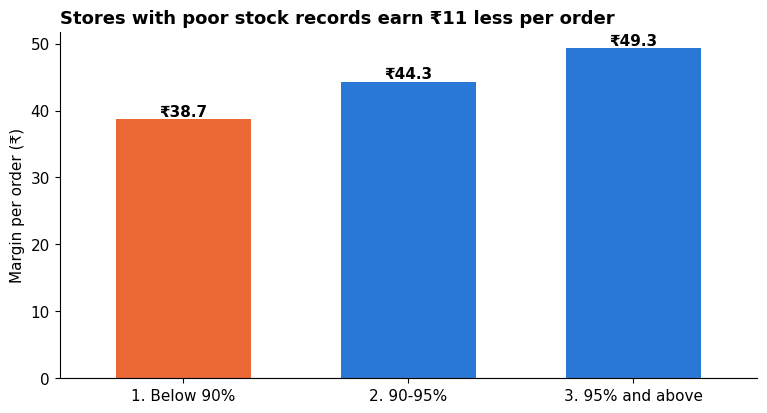

In [25]:
bar_chart(inv, "stock_accuracy", "margin_per_order", "Stores with poor stock records earn ₹11 less per order",
          "Margin per order (₹)", highlight=[0], fmt="₹{:.1f}", fname="5_stock_accuracy")

In [26]:
df = run("""
SELECT CASE WHEN s.staffing_fill_rate_pct < 80 THEN '1. Below 80%'
            WHEN s.staffing_fill_rate_pct < 90 THEN '2. 80-90%'
            ELSE '3. 90% and above' END   AS shifts_filled,
       COUNT(DISTINCT s.store_id)         AS stores,
       ROUND(100.0 * AVG(o.late_delivery_flag), 1) AS pct_late
FROM orders o
JOIN stores s ON o.store_id = s.store_id
GROUP BY shifts_filled
ORDER BY shifts_filled
""")
df

,shifts_filled,stores,pct_late
0,1. Below 80%,12,22.0
1,2. 80-90%,11,16.3
2,3. 90% and above,13,13.9


In [27]:
df = run("""
SELECT s.store_id, s.city, s.inventory_accuracy_pct, s.staffing_fill_rate_pct,
       COUNT(*) AS orders,
       ROUND(AVG(o.contribution_margin_inr), 1) AS margin_per_order,
       ROUND(100.0 * AVG(o.late_delivery_flag), 1) AS pct_late
FROM orders o
JOIN stores s ON o.store_id = s.store_id
GROUP BY s.store_id
ORDER BY margin_per_order
LIMIT 6
""")
df

,store_id,city,inventory_accuracy_pct,staffing_fill_rate_pct,orders,margin_per_order,pct_late
0,S012,Tier2 D,88.8,76.9,860,33.3,30.2
1,S011,Tier2 E,84.5,76.5,829,35.2,30.7
2,S027,Metro A,88.7,78.2,775,35.3,23.8
3,S003,Tier2 D,89.5,69.8,797,38.7,25.5
4,S008,Metro C,90.9,96.2,839,39.1,17.2
5,S016,Tier2 D,89.0,97.3,834,39.5,13.7


In [28]:
df = run("""
SELECT 'City' AS split, s.city AS grp, ROUND(AVG(o.contribution_margin_inr), 1) AS margin_per_order
FROM orders o JOIN stores s ON o.store_id = s.store_id GROUP BY s.city
UNION ALL
SELECT 'Delivery model', s.delivery_partner_model, ROUND(AVG(o.contribution_margin_inr), 1)
FROM orders o JOIN stores s ON o.store_id = s.store_id GROUP BY s.delivery_partner_model
UNION ALL
SELECT 'Store opened in', strftime('%Y', s.launch_date), ROUND(AVG(o.contribution_margin_inr), 1)
FROM orders o JOIN stores s ON o.store_id = s.store_id GROUP BY strftime('%Y', s.launch_date)
""")
df

,split,grp,margin_per_order
0,City,Metro A,45.1
1,City,Metro B,43.5
2,City,Metro C,46.2
3,City,Tier2 D,42.4
4,City,Tier2 E,43.4
5,City,Tier2 F,46.9
6,Delivery model,Dedicated,44.3
7,Delivery model,Hybrid,44.3
8,Delivery model,Marketplace,44.3
9,Store opened in,2023,45.3


What I see:
- **The delivery promise doesn't depend on distance.** 20-, 25- and 30-minute promises all go to orders with the same average distance (2.5 km). So 20-minute promises are late 40% of the time overall, and 72% of the time beyond 4 km.
- **Rain at peak hours is the worst slot:** 47.5% late, against 6.9% at normal off-peak times.
- **Late orders cost us:** rating 3.88 vs 4.28, and 18.8% of late orders contact support vs 11.1%.
- **Missing items lead to refunds.** With nothing missing the average refund is ₹10; with one item missing it's ₹28. Ratings drop from 4.95 to 2.94 when three or more items are missing.
- **Stock accuracy explains a lot of the store gap.** The 9 stores whose stock records are below 90% accurate earn ₹38.7 per order, against ₹49.3 for stores at 95%+.
- **Under-staffed stores are late more often** (22% vs 14%).
- City, delivery model and store age make only small differences, so the fix is inside the stores, not in where they are.

## Step 5 · The promotion: who should get an offer? (Ask 4)
The Q1 campaign was a proper experiment. Customers were randomly put in a **Control** group (no offer) or a **Treatment** group (one of three offers). Because it was random, the two groups are alike, so any difference after the campaign is caused by the offer.

The key idea: an offer only pays if it brings in **extra** profit compared with doing nothing. Redemption alone doesn't tell us that, because some people would have bought anyway.

In [29]:
df = run("""
SELECT a.offer_type,
       COUNT(*) AS customers,
       ROUND(AVG(c.days_since_last_order), 0) AS avg_days_since_last_order,
       ROUND(AVG(c.app_sessions_30d), 1)      AS avg_app_sessions,
       ROUND(AVG(c.historical_orders_12m), 1) AS avg_orders_2025
FROM campaign_assignments a
JOIN customers c ON a.customer_id = c.customer_id
GROUP BY a.offer_type
""")
df

,offer_type,customers,avg_days_since_last_order,avg_app_sessions,avg_orders_2025
0,Fixed discount,1573,109.0,8.2,3.7
1,Free delivery,1559,107.0,8.2,3.7
2,No offer,2832,106.0,8.3,3.8
3,Percentage discount,2036,105.0,8.4,3.8


In [30]:
df = run("""
SELECT assignment_group,
       COUNT(*) AS customers,
       ROUND(AVG(post_campaign_orders), 2)     AS orders_per_customer,
       ROUND(AVG(post_campaign_margin_inr), 1) AS margin_per_customer
FROM campaign_assignments
GROUP BY assignment_group
""")
df

,assignment_group,customers,orders_per_customer,margin_per_customer
0,Control,2832,1.21,78.8
1,Treatment,5168,1.37,66.4


In [31]:
df = run("""
SELECT offer_type,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(offer_redeemed_flag), 1) AS pct_redeemed,
       ROUND(AVG(post_campaign_orders), 2)        AS orders_per_customer,
       ROUND(AVG(post_campaign_margin_inr), 1)    AS margin_per_customer
FROM campaign_assignments
GROUP BY offer_type
ORDER BY margin_per_customer DESC
""")
df

,offer_type,customers,pct_redeemed,orders_per_customer,margin_per_customer
0,No offer,2832,0.0,1.21,78.8
1,Free delivery,1559,31.8,1.37,76.7
2,Percentage discount,2036,32.0,1.35,64.7
3,Fixed discount,1573,31.7,1.38,58.2


In [32]:
promo = run("""
SELECT CASE WHEN c.days_since_last_order <= 90 THEN '1. Active (ordered in last 90 days)'
            ELSE '2. Lapsed (no order for 91+ days)' END AS customer_type,
       a.offer_type,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(a.offer_redeemed_flag), 1) AS pct_redeemed,
       ROUND(AVG(a.post_campaign_orders), 2)        AS orders_per_customer,
       ROUND(AVG(a.post_campaign_margin_inr), 1)    AS margin_per_customer
FROM campaign_assignments a
JOIN customers c ON a.customer_id = c.customer_id
GROUP BY customer_type, a.offer_type
ORDER BY customer_type, a.offer_type
""")
promo

,customer_type,offer_type,customers,pct_redeemed,orders_per_customer,margin_per_customer
0,1. Active (ordered in last 90 days),Fixed discount,821,37.6,1.71,73.1
1,1. Active (ordered in last 90 days),Free delivery,835,36.3,1.73,98.2
2,1. Active (ordered in last 90 days),No offer,1515,0.0,1.62,106.2
3,1. Active (ordered in last 90 days),Percentage discount,1111,36.5,1.70,84.5
4,2. Lapsed (no order for 91+ days),Fixed discount,752,25.1,1.02,41.9
5,2. Lapsed (no order for 91+ days),Free delivery,724,26.5,0.95,52.0
6,2. Lapsed (no order for 91+ days),No offer,1317,0.0,0.73,47.3
7,2. Lapsed (no order for 91+ days),Percentage discount,925,26.5,0.93,41.0


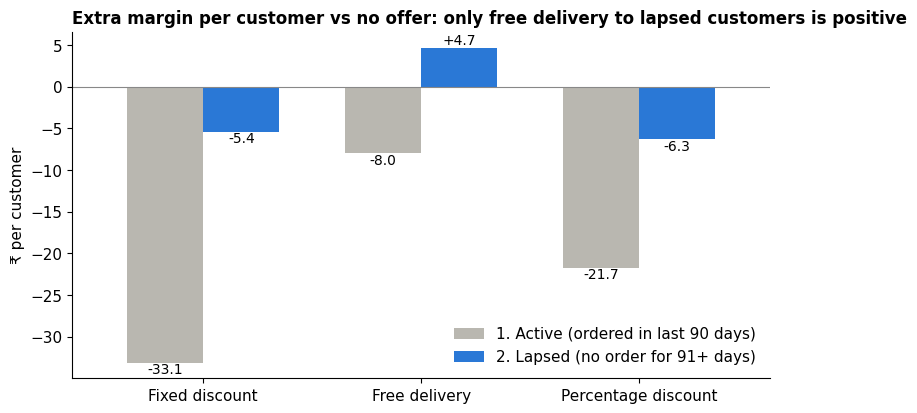

,customer_type,offer_type,pct_redeemed,extra_margin_vs_no_offer
0,1. Active (ordered in last 90 days),Fixed discount,37.6,-33.1
1,1. Active (ordered in last 90 days),Free delivery,36.3,-8.0
3,1. Active (ordered in last 90 days),Percentage discount,36.5,-21.7
4,2. Lapsed (no order for 91+ days),Fixed discount,25.1,-5.4
5,2. Lapsed (no order for 91+ days),Free delivery,26.5,4.7
7,2. Lapsed (no order for 91+ days),Percentage discount,26.5,-6.3


In [33]:
# Extra margin = offer group's margin minus the no-offer group's margin, within the same customer type
base = promo[promo.offer_type == "No offer"].set_index("customer_type")["margin_per_customer"]
promo["extra_margin_vs_no_offer"] = promo.apply(lambda r: round(r.margin_per_customer - base[r.customer_type], 1), axis=1)
result = promo[promo.offer_type != "No offer"][["customer_type", "offer_type", "pct_redeemed", "extra_margin_vs_no_offer"]]

table = result.pivot(index="offer_type", columns="customer_type", values="extra_margin_vs_no_offer")
ax = table.plot(kind="bar", rot=0, color=[GREY, BLUE], width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt="%+.1f", fontsize=10)
ax.axhline(0, color="#888", linewidth=0.8)
ax.set_title("Extra margin per customer vs no offer: only free delivery to lapsed customers is positive", loc="left", fontsize=12)
ax.set_ylabel("₹ per customer"); ax.set_xlabel(""); ax.legend(title="", frameon=False)
plt.savefig(f"{CHARTS}/6_promo_result.png", dpi=200, bbox_inches="tight"); plt.show()
result

What I see:
- **As run, the campaign lost money.** Treatment customers ordered a bit more (1.37 vs 1.21 orders) but gave ₹66.4 of margin each, against ₹78.8 in control. The exact gap is **₹12.5 less per customer** (Step 6 prints it).
- **Redemption is misleading.** Active customers redeemed most (about 37%), but every offer *lowered* their margin. They would have ordered anyway, so we just paid for orders we already had.
- **Lapsed customers + free delivery is the only positive cell:** ₹4.7 more margin per customer and 0.22 more orders. This is also the cheapest offer (₹39).
- Caution: each cell has about 700-1,500 customers, and ₹4.7 is a small gain. That's enough to point the way, but I'd re-test it before a full rollout.

## Step 6 · Recommendations for next quarter
I sized each idea with simple arithmetic on the numbers above.

In [34]:
# 1) Promo: free delivery only for lapsed customers
lapsed_share = run("SELECT AVG(CASE WHEN days_since_last_order > 90 THEN 1.0 ELSE 0 END) AS s FROM customers").s[0]
as_run = run("""SELECT AVG(CASE WHEN assignment_group='Treatment' THEN post_campaign_margin_inr END)
                     - AVG(CASE WHEN assignment_group='Control' THEN post_campaign_margin_inr END) AS d
                FROM campaign_assignments""").d[0]
lapsed_gain = result[(result.customer_type.str.startswith("2")) & (result.offer_type == "Free delivery")].extra_margin_vs_no_offer.iloc[0]
print(f"Per 1,000 customers, campaign as run:          ₹{as_run * 1000:,.0f}")
print(f"Per 1,000 customers, free delivery to lapsed:  ₹{lapsed_gain * lapsed_share * 1000:,.0f}  ({lapsed_share:.1%} of customers get the offer)")

Per 1,000 customers, campaign as run:          ₹-12,461
Per 1,000 customers, free delivery to lapsed:  ₹2,184  (46.5% of customers get the offer)


In [35]:
# 2) Delivery promise by distance: 25 min within 2 km, 30 min beyond.
#    Use today's late rates for that distance and promise to estimate the new late rate.
late = promise.set_index(["distance", "promised_minutes"])["pct_late"]
orders_by_band = promise.groupby("distance")["orders"].sum()
new_rule = {"1. 0-2 km": 25, "2. 2-4 km": 30, "3. over 4 km": 30}
new_late = sum(late[(band, mins)] * orders_by_band[band] for band, mins in new_rule.items()) / orders_by_band.sum()
print(f"Late deliveries today: {kpi.pct_late[0]}%   With the new promise rule: {new_late:.1f}%")

Late deliveries today: 17.3%   With the new promise rule: 7.1%


In [36]:
# 3) Stock accuracy: if the 9 weakest stores did as well as the 90-95% group
weak, middle = inv.iloc[0], inv.iloc[1]
gain_per_order = middle.margin_per_order - weak.margin_per_order
total_margin = run("SELECT SUM(contribution_margin_inr) AS t FROM orders").t[0]
extra = gain_per_order * weak.orders
print(f"₹{gain_per_order:.1f} more per order x {weak.orders:,} orders = ₹{extra:,.0f} = {extra / total_margin:.1%} of total margin")

₹5.6 more per order x 7,414 orders = ₹41,518 = 3.1% of total margin


| # | Action | Who | Expected effect | Trade-off | How to test it first |
|---|---|---|---|---|---|
| 1 | Stop sending offers to active customers. Send **free delivery only to lapsed customers** (no order for 91+ days) | About 46.5% of customers | From losing about ₹12,460 per 1,000 customers to gaining about ₹2,200, and about 0.2 more orders per lapsed customer | Fewer people use offers, so order counts look lower | Run it again with a random control group and judge it on margin, not redemption |
| 2 | **Make the delivery promise depend on distance:** 25 minutes within 2 km, 30 minutes beyond | All orders | Late deliveries fall from about 17% to about 7% | Customers see a longer promise, which might put some off | Try it in a few stores first and compare orders, late rate and ratings with similar stores |
| 3 | **Fix stock records in the 9 stores below 90% accuracy** (regular stock counts) | 9 stores, including S011, S012, S027 and S019 | About ₹5.6 more per order, roughly +3% of total margin; fewer refunds and better ratings | Staff time for regular counts | Start with 3-4 of these stores and compare with the others for 6 weeks |

Context from outside the case (labelled sources):
- In January 2026 Blinkit, Zepto and other quick-commerce apps agreed to drop their "10-minute delivery" claims after Labour Minister Mansukh Mandaviya raised rider safety (Outlook Business, 13 Jan 2026). Unrealistic delivery promises are a real-world risk too.
- Blinkit has been EBITDA-positive since Q3 FY26, and its contribution margin rose from 3.9% to 5.4% of net order value (Datum Intelligence, Jun 2026). In quick commerce, margin per order is what the market watches.

## Step 7 · Double-check with plain Python
I re-calculate a few key numbers a different way to make sure the SQL is right.

In [37]:
orders = pd.read_excel(excel_file, sheet_name="orders")
camp = pd.read_excel(excel_file, sheet_name="campaign_assignments")
checks = pd.DataFrame({
    "number": ["Margin per order (₹)", "% orders late", "% orders losing money", "Campaign: treatment minus control (₹)"],
    "from SQL": [kpi.margin_per_order_inr[0], kpi.pct_late[0], kpi.pct_orders_losing_money[0], round(as_run, 1)],
    "from Python": [round(orders.contribution_margin_inr.mean(), 1), round(100 * orders.late_delivery_flag.mean(), 1),
                    round(100 * (orders.contribution_margin_inr < 0).mean(), 1),
                    round(camp[camp.assignment_group == "Treatment"].post_campaign_margin_inr.mean()
                          - camp[camp.assignment_group == "Control"].post_campaign_margin_inr.mean(), 1)]})
checks["match"] = checks["from SQL"] == checks["from Python"]
checks

,number,from SQL,from Python,match
0,Margin per order (₹),44.3,44.3,True
1,% orders late,17.3,17.3,True
2,% orders losing money,21.0,21.0,True
3,Campaign: treatment minus control (₹),-12.5,-12.5,True
